# Leyenda: Deliverable 1, binary classification of Photo vs non-Photo

## 1. Business context

TouNum digitises paper document collections for companies and wants to add automatic categorisation to its services. Its end goal is to caption photographs automatically, but the scanned archives also contain composed documents, diagrams, drawings and paintings. Photos must therefore be separated from the other image types before any content analysis.

### Task

Binary classification with neural networks: Photo = 1 against Painting, Schematics, Sketch and Text = 0, on images TouNum has already categorised.

### Content of this notebook

We start from two reference models (majority class, and a decision tree on image metadata), then train an MLP, a CNN from scratch with improvement methods, and a pretrained MobileNetV2. Models are selected on validation only; the test set is scored once per model, on its natural distribution, and never used to make a choice.

In [1]:
import io
import os
import time
import hashlib
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import PIL
from PIL import Image
import sklearn
from sklearn.metrics import (average_precision_score, balanced_accuracy_score,
                             confusion_matrix, precision_recall_fscore_support)
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
import tensorflow as tf
import keras
from IPython.display import Image as ShowImage

T0 = time.time()
gpus = tf.config.list_physical_devices("GPU")
if not gpus:
    raise SystemExit("No GPU found by TensorFlow: check the kernel and the CUDA libraries before running this notebook.")
tf.config.experimental.set_memory_growth(gpus[0], True)
GPU_NAME = tf.config.experimental.get_device_details(gpus[0]).get("device_name", "unknown")
print("GPU:", GPU_NAME)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| numpy", np.__version__,
      "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__,
      "| matplotlib", matplotlib.__version__, "| Pillow", PIL.__version__)

DATA_DIR, CACHE, REPORTS, MODELS = Path("data/Datasets"), Path("cache"), Path("reports"), Path("models")
for d in [CACHE, REPORTS, MODELS]:
    d.mkdir(exist_ok=True)
SEED, SIZE, BATCH, MIN_SIDE_PX, NOISE = 42, 128, 32, 32, 0.03
METRICS = ["precision", "recall", "f1", "balanced_acc", "pr_auc", "accuracy"]

I0000 00:00:1791574422.566422  511176 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791574424.721292  511176 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


GPU: NVIDIA GeForce RTX 5060 Laptop GPU
TensorFlow 2.22.0-rc0 | Keras 3.16.0.dev2026100504 | numpy 2.5.3 | pandas 3.0.6 | scikit-learn 1.9.1 | matplotlib 3.11.2 | Pillow 12.3.0


### Helpers

The five helpers load images with a disk cache, compute class weights from the training labels only, plot loss and accuracy curves, and list the layers of a model with their parameter counts (describe_model). evaluate returns the metrics at a 0.5 threshold, the confusion matrix and the error rate by origin.

In [2]:
def _load_one(path, size):
    with Image.open(DATA_DIR / path) as im:
        return np.asarray(im.convert("RGB").resize((size, size), Image.BILINEAR), dtype=np.uint8)

def load_images(df, size=SIZE):
    """RGB uint8 array (n, size, size, 3), cached in cache/ (key = list of paths + size)."""
    key = hashlib.md5(("|".join(df["path"]) + f"|{size}").encode()).hexdigest()[:12]
    fp = CACHE / f"images_{size}_{len(df)}_{key}.npy"
    if fp.exists():
        return np.load(fp)
    with ThreadPoolExecutor(8) as ex:
        X = np.stack(list(ex.map(lambda p: _load_one(p, size), df["path"])))
    np.save(fp, X)
    return X

def class_weights(y_train):
    """Balanced weights n / (2 * n_c), from training labels only."""
    n, n1 = len(y_train), int(np.sum(y_train))
    return {0: n / (2 * (n - n1)), 1: n / (2 * n1)}

def evaluate(y_true, proba, origin, threshold=0.5):
    """Metrics at a fixed threshold (PR-AUC uses the probabilities), confusion matrix, and error rate by origin."""
    y_true, proba = np.asarray(y_true), np.asarray(proba).ravel()
    y_pred = (proba >= threshold).astype(int)
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=[1], zero_division=0)
    err = pd.Series(y_pred != y_true, index=np.asarray(origin)).groupby(level=0).mean()
    return {"precision": p[0], "recall": r[0], "f1": f[0],
            "balanced_acc": balanced_accuracy_score(y_true, y_pred),
            "pr_auc": average_precision_score(y_true, proba),
            "accuracy": (y_pred == y_true).mean(),
            "cm": confusion_matrix(y_true, y_pred, labels=[0, 1]),
            "error_by_origin": err}

def plot_curves(history, title="", axes=None):
    """Train/validation loss and accuracy per epoch from a Keras history dict."""
    if axes is None:
        _, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    epochs = np.arange(1, len(history["loss"]) + 1)
    for ax, m in zip(axes, ["loss", "accuracy"]):
        ax.plot(epochs, history[m], color="#2a78d6", lw=2, marker="o", ms=4, label="train")
        ax.plot(epochs, history[f"val_{m}"], color="#eb6834", lw=2, marker="o", ms=4, label="validation")
        ax.set(title=f"{title} - {m}".strip(" -"), xlabel="epoch")
        ax.grid(alpha=0.3)
        ax.spines[["top", "right"]].set_visible(False)
    axes[0].legend(frameon=False)
    return axes

def describe_model(model):
    """One row per top-level layer; prints total, trainable and non-trainable parameter counts."""
    table = pd.DataFrame([{"name": l.name, "type": type(l).__name__, "output shape": str(tuple(l.output.shape)),
                           "params": l.count_params()} for l in model.layers])
    total = model.count_params()
    trainable = int(sum(np.prod(w.shape) for w in model.trainable_weights))
    print(f"Total {total:,} | trainable {trainable:,} | non-trainable {total - trainable:,}")
    return table

## 2. Data processing

Every file of the five origin folders is read once: MD5 of the bytes, width, height, colour mode, and a full decode to catch unreadable files. The label is 1 for the Photo folder and 0 for the others. The result is cached in cache/.

In [3]:
def inspect(fp):
    data = fp.read_bytes()
    row = {"md5": hashlib.md5(data).hexdigest(), "width": np.nan, "height": np.nan, "mode": "", "drop_reason": ""}
    if fp.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
        row["drop_reason"] = "not_an_image"
        return row
    try:
        with Image.open(io.BytesIO(data)) as im:
            row["width"], row["height"], row["mode"] = im.size[0], im.size[1], im.mode
            im.load()  # decodes every pixel
    except Exception:
        row["drop_reason"] = "unreadable"
    return row

ORIGINS = sorted(p.name for p in DATA_DIR.iterdir() if p.is_dir())
files = [(o, fp) for o in ORIGINS for fp in sorted((DATA_DIR / o).iterdir()) if fp.is_file()]
paths = [fp.relative_to(DATA_DIR).as_posix() for _, fp in files]
inv_cache = CACHE / f"inventory_{len(files)}_{hashlib.md5('|'.join(paths).encode()).hexdigest()[:12]}.csv"
if inv_cache.exists():
    df = pd.read_csv(inv_cache, dtype={"md5": str, "mode": str, "drop_reason": str})
    df[["mode", "drop_reason"]] = df[["mode", "drop_reason"]].fillna("")
else:
    with ThreadPoolExecutor(16) as ex:
        df = pd.DataFrame(list(ex.map(lambda t: inspect(t[1]), files)))
    df.insert(0, "path", paths)
    df.insert(1, "origin", [o for o, _ in files])
    df.insert(2, "label", (df["origin"] == "Photo").astype(int))
    df.insert(3, "ext", [fp.suffix.lower().lstrip(".") for _, fp in files])
    df.to_csv(inv_cache, index=False)

print(f"{len(df)} files, {(df['drop_reason'] != '').sum()} not an image or unreadable")
display(pd.crosstab(df["origin"], df["ext"], margins=True, margins_name="total"))
display(pd.crosstab(df["origin"], df["mode"], margins=True, margins_name="total"))
df["min_side"] = df[["width", "height"]].min(axis=1)
df.groupby("origin")["min_side"].describe(percentiles=[0.01, 0.5])[["min", "1%", "50%", "max"]].astype(int)

41399 files, 0 not an image or unreadable


ext,jpg,png,total
origin,,,
Painting,10000,0,10000
Photo,9993,0,9993
Schematics,10000,0,10000
Sketch,606,800,1406
Text,10000,0,10000
total,40599,800,41399


mode,CMYK,L,P,RGB,RGBA,total
origin,,,,,,
Painting,1,82,5,9907,5,10000
Photo,0,25,0,9968,0,9993
Schematics,0,116,0,9884,0,10000
Sketch,0,868,0,538,0,1406
Text,0,0,0,10000,0,10000
total,1,1091,5,40297,5,41399


,min,1%,50%,max
origin,,,,
Painting,201,317,712,6232
Photo,109,281,428,640
Schematics,1,3,441,7273
Sketch,411,411,1111,1111
Text,360,360,595,612


Exact duplicates share the same MD5: the first path in alphabetical order is kept and the others are dropped; no group had two labels.

Choice: drop images whose shortest side is under 32 px, after deduplication. Why: the 401 dropped images are all Schematics, and reaching 128 px from under 32 px means an upscaling of more than 4x. Alternative not taken: keep them and upsample; 16 or 64 px were not tested (counts in the table below).

In [4]:
readable = df["drop_reason"] == ""
sub = df[readable].sort_values("path")
groups = sub.groupby("md5")
group_size, n_labels, rank = groups["path"].transform("size"), groups["label"].transform("nunique"), groups.cumcount()
df.loc[sub.index[((group_size > 1) & (n_labels > 1)).to_numpy()], "drop_reason"] = "label_conflict"
df.loc[sub.index[((group_size > 1) & (n_labels == 1) & (rank > 0)).to_numpy()], "drop_reason"] = "exact_duplicate"
print(f"MD5 groups with more than one file: {(groups.size() > 1).sum()}")

too_small = (df["drop_reason"] == "") & (df["min_side"] < MIN_SIDE_PX)
df.loc[too_small, "drop_reason"] = "too_small"
display(pd.crosstab(df["origin"], df["drop_reason"].replace("", "(kept)"), margins=True, margins_name="total"))
# Images below each side length, after deduplication (same population as the size filter above)
after_dedup = df["drop_reason"].isin(["", "too_small"])
display(pd.DataFrame({f"< {t} px": (df.loc[after_dedup, "min_side"] < t).groupby(df.loc[after_dedup, "origin"]).sum() for t in [16, 32, 64]}))

MD5 groups with more than one file: 380


drop_reason,(kept),exact_duplicate,too_small,total
origin,,,,
Painting,9996,4,0,10000
Photo,9993,0,0,9993
Schematics,8908,691,401,10000
Sketch,1406,0,0,1406
Text,9999,1,0,10000
total,40302,696,401,41399


,< 16 px,< 32 px,< 64 px
origin,,,
Painting,0,0,0
Photo,0,0,0
Schematics,275,401,621
Sketch,0,0,0
Text,0,0,0


Choice: 70/15/15 stratified by origin, seed 42. Why: with 1,406 Sketch images, 15% leaves 211 Sketch images in each of validation and test. Alternative not taken: 80/10/10, about 140 Sketch images per evaluation set.

In [5]:
kept = df["drop_reason"] == ""
idx_train, idx_tmp = train_test_split(df.index[kept], test_size=0.30, stratify=df.loc[kept, "origin"], random_state=SEED)
idx_val, idx_test = train_test_split(idx_tmp, test_size=0.50, stratify=df.loc[idx_tmp, "origin"], random_state=SEED)
df["split"] = ""
df.loc[idx_train, "split"], df.loc[idx_val, "split"], df.loc[idx_test, "split"] = "train", "val", "test"

splits_per_md5 = df[kept].groupby("md5")["split"].nunique()
assert (splits_per_md5 == 1).all(), "The same MD5 is present in several splits"
print(f"Leakage check OK: {splits_per_md5.size} distinct MD5s, none in two splits")

data_summary = pd.crosstab(df.loc[kept, "origin"], df.loc[kept, "split"], margins=True, margins_name="total")[["train", "val", "test", "total"]]
display(data_summary)
photo_share = (df.loc[df["split"] == "test", "label"] == 1).mean()
print(f"Photo share of the test set: {photo_share:.4f} -> majority-class accuracy {1 - photo_share:.4f}")

Leakage check OK: 40302 distinct MD5s, none in two splits


split,train,val,test,total
origin,,,,
Painting,6997,1499,1500,9996
Photo,6995,1499,1499,9993
Schematics,6236,1336,1336,8908
Sketch,984,211,211,1406
Text,6999,1500,1500,9999
total,28211,6045,6046,40302


Photo share of the test set: 0.2479 -> majority-class accuracy 0.7521


## 3. Reference models

The two reference models are the majority class (always non-Photo) and a decision tree that sees only width, height, aspect ratio and colour mode. Both are scored on the test set here, once, and reused in the final table.

Choice: tree depth 1 to 12 chosen on validation balanced accuracy, balanced class weights. Why: the validation score is flat from depth 7 to 12, so depth 10 is a tie-break, not a finding. Alternative not taken: tuning other tree hyperparameters; the tree is only a reference.

In [6]:
splits = {s: df[df["split"] == s].reset_index(drop=True) for s in ["train", "val", "test"]}
y = {s: d["label"].to_numpy() for s, d in splits.items()}
origin = {s: d["origin"].to_numpy() for s, d in splits.items()}
cw = class_weights(y["train"])
MODES = sorted(df.loc[kept, "mode"].unique())  # column names only; no values from val/test are used

def meta_features(d):
    f = pd.DataFrame({"width": d["width"], "height": d["height"], "ratio": d["width"] / d["height"]})
    for m in MODES:
        f[f"mode_{m}"] = (d["mode"] == m).astype(int)
    return f

F = {s: meta_features(d) for s, d in splits.items()}
val_bacc = {}
for depth in range(1, 13):
    tree = DecisionTreeClassifier(max_depth=depth, class_weight=cw, random_state=SEED).fit(F["train"], y["train"])
    val_bacc[depth] = balanced_accuracy_score(y["val"], tree.predict(F["val"]))
best_depth = max(val_bacc, key=val_bacc.get)
print("Validation balanced accuracy by depth:", {k: round(v, 4) for k, v in val_bacc.items()})
print("Selected depth:", best_depth)
tree = DecisionTreeClassifier(max_depth=best_depth, class_weight=cw, random_state=SEED).fit(F["train"], y["train"])

test_eval = {"majority": evaluate(y["test"], np.zeros(len(y["test"])), origin["test"]),
             "decision tree (metadata)": evaluate(y["test"], tree.predict_proba(F["test"])[:, 1], origin["test"])}
print(f"Test set (n = {len(y['test'])})")
pd.DataFrame({k: {m: v[m] for m in METRICS} for k, v in test_eval.items()}).T.round(4)

Validation balanced accuracy by depth: {1: 0.8165, 2: 0.8718, 3: 0.9216, 4: 0.9256, 5: 0.9256, 6: 0.9711, 7: 0.9817, 8: 0.983, 9: 0.982, 10: 0.9835, 11: 0.9835, 12: 0.9832}
Selected depth: 10
Test set (n = 6046)


,precision,recall,f1,balanced_acc,pr_auc,accuracy
majority,0.0000,0.0000,0.0000,0.5000,0.2479,0.7521
decision tree (metadata),0.9641,0.9853,0.9746,0.9866,0.9849,0.9873


Choice: balanced accuracy is the main metric. Why: the majority class gets 0.75 accuracy but 0.50 balanced accuracy. Alternative not taken: accuracy alone.

In [7]:
# Ablation on validation only: which inputs carry the signal (same depth, same weights)
groups_cols = {"dimensions only": ["width", "height", "ratio"],
               "colour mode only": [col for col in F["train"] if col.startswith("mode_")],
               "all": list(F["train"])}
ablation = {}
for name, cols in groups_cols.items():
    t = DecisionTreeClassifier(max_depth=best_depth, class_weight=cw, random_state=SEED).fit(F["train"][cols], y["train"])
    ablation[name] = balanced_accuracy_score(y["val"], t.predict(F["val"][cols]))
pd.Series(ablation, name="val balanced_acc").round(4).to_frame()

,val balanced_acc
dimensions only,0.9835
colour mode only,0.5162
all,0.9835


**What we see.** On validation, the tree with dimensions alone scores 0.98 balanced accuracy, the same as with all inputs; colour mode alone scores 0.52, near chance.

**What it means.** The metadata tree is the bar the networks must reach: Photo shortest sides never exceed 640 px while Painting and Sketch have larger medians (size table, section 2), so size alone separates most origins. The 128x128 resize hides the absolute size, so we do not know whether the networks use it as a shortcut.

## 4. Neural networks

Choice: 128x128 RGB, aspect ratio not kept. Why: one common size is needed for batching, and the Photo median shortest side is 428 px, about a 3x reduction. Alternative not taken: 224x224, not tested.

Images stay uint8 and each model rescales them itself. Validation is passed with the same class weights as training (sample_weight), so train and validation losses are comparable; the accuracy metric is not weighted.

In [8]:
t = time.time()
X = {s: load_images(d, SIZE) for s, d in splits.items()}
for s in X:
    print(s, X[s].shape, X[s].dtype)
print(f"Loaded in {time.time() - t:.0f} s | class weights:", {k: round(v, 3) for k, v in cw.items()})
sw_val = np.where(y["val"] == 1, cw[1], cw[0])

def train(name, model, epochs, callbacks=()):
    t = time.time()
    hist = model.fit(X["train"], y["train"], validation_data=(X["val"], y["val"], sw_val), epochs=epochs,
                     batch_size=BATCH, class_weight=cw, callbacks=list(callbacks), verbose=0)
    val = evaluate(y["val"], model.predict(X["val"], verbose=0), origin["val"])
    train_acc = ((model.predict(X["train"], verbose=0).ravel() >= 0.5) == y["train"]).mean()
    r = {"model": model, "history": hist.history, "val": val, "train_acc": train_acc,
         "epochs": len(hist.history["loss"]), "params": model.count_params()}
    print(f"{name:24s}: {time.time() - t:4.0f} s | {r['epochs']:2d} epochs | {r['params']:>9,} params | "
          f"train acc {train_acc:.4f} | val acc {val['accuracy']:.4f} | val balanced acc {val['balanced_acc']:.4f}")
    return r

runs = {}

train (28211, 128, 128, 3) uint8
val (6045, 128, 128, 3) uint8
test (6046, 128, 128, 3) uint8
Loaded in 3 s | class weights: {0: 0.665, 1: 2.017}


The MLP flattens the 49,152 pixel values into Dense(128) and Dense(64); it has no notion of neighbouring pixels.

Choice: 15 epochs for the MLP, 20 for the CNN. Why: fixed in the development notebooks, not adjusted on the validation set of this notebook. Alternative not taken: the same number for both.

Total 6,299,905 | trainable 6,299,905 | non-trainable 0


,name,type,output shape,params
0,rescaling,Rescaling,"(None, 128, 128, 3)",0
1,flatten,Flatten,"(None, 49152)",0
2,dense,Dense,"(None, 128)",6291584
3,dense_1,Dense,"(None, 64)",8256
4,dense_2,Dense,"(None, 1)",65


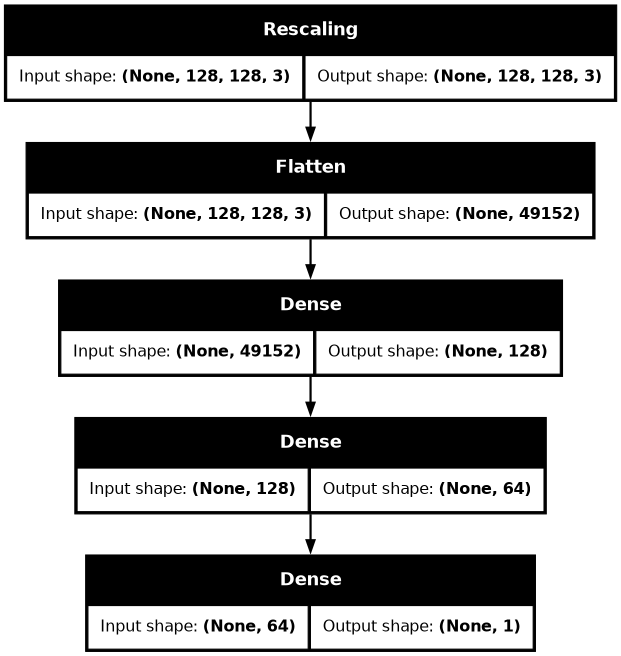

MLP                     :   71 s | 15 epochs | 6,299,905 params | train acc 0.7761 | val acc 0.7661 | val balanced acc 0.8078


In [9]:
def build_mlp():
    keras.utils.set_random_seed(SEED)
    model = keras.Sequential([keras.Input((SIZE, SIZE, 3)), keras.layers.Rescaling(1 / 255), keras.layers.Flatten(),
                              keras.layers.Dense(128, activation="relu"), keras.layers.Dense(64, activation="relu"),
                              keras.layers.Dense(1, activation="sigmoid")], name="mlp")
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy", metrics=["accuracy"])
    return model

mlp = build_mlp()
display(describe_model(mlp))
keras.utils.plot_model(mlp, to_file=str(REPORTS / "final_mlp_architecture.png"), show_shapes=True, dpi=80)
display(ShowImage(str(REPORTS / "final_mlp_architecture.png")))
runs["MLP"] = train("MLP", mlp, 15)

The CNN baseline has three Conv2D(3x3) + MaxPooling blocks (16, 32, 64 filters) that shrink the image to 14x14x64, then Flatten, Dense(64) and a sigmoid output.
Convolution filters share their weights across positions, so most parameters sit in the Dense(64) layer after Flatten.
The build function takes one flag per improvement tested in section 6; the baseline uses none.

Total 826,529 | trainable 826,529 | non-trainable 0


,name,type,output shape,params
0,rescaling_1,Rescaling,"(None, 128, 128, 3)",0
1,conv2d,Conv2D,"(None, 126, 126, 16)",448
2,max_pooling2d,MaxPooling2D,"(None, 63, 63, 16)",0
3,conv2d_1,Conv2D,"(None, 61, 61, 32)",4640
4,max_pooling2d_1,MaxPooling2D,"(None, 30, 30, 32)",0
5,conv2d_2,Conv2D,"(None, 28, 28, 64)",18496
6,max_pooling2d_2,MaxPooling2D,"(None, 14, 14, 64)",0
7,flatten_1,Flatten,"(None, 12544)",0
8,dense_3,Dense,"(None, 64)",802880
9,dense_4,Dense,"(None, 1)",65


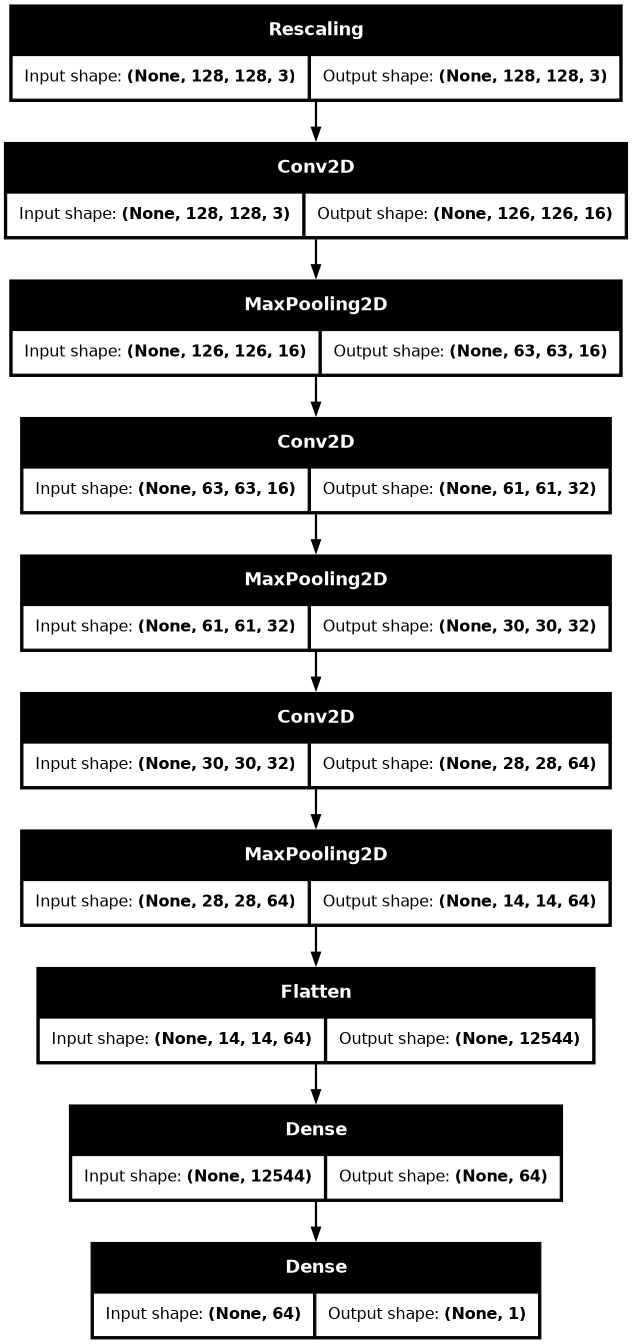

In [10]:
def build_cnn(name, dropout=False, l2=False, augment=False, gap=False):
    keras.utils.set_random_seed(SEED)
    reg = keras.regularizers.l2(1e-4) if l2 else None
    layers = [keras.Input((SIZE, SIZE, 3)), keras.layers.Rescaling(1 / 255)]
    if augment:  # active only in training
        layers += [keras.layers.RandomFlip("horizontal", seed=SEED), keras.layers.RandomRotation(0.05, seed=SEED),
                   keras.layers.RandomZoom(0.1, seed=SEED)]
    for filters in [16, 32, 64]:
        layers += [keras.layers.Conv2D(filters, 3, activation="relu", kernel_regularizer=reg), keras.layers.MaxPooling2D()]
    layers += [keras.layers.GlobalAveragePooling2D() if gap else keras.layers.Flatten(),
               keras.layers.Dense(64, activation="relu", kernel_regularizer=reg)]
    if dropout:
        layers.append(keras.layers.Dropout(0.5))
    layers.append(keras.layers.Dense(1, activation="sigmoid", kernel_regularizer=reg))
    model = keras.Sequential(layers, name="".join(c if c.isalnum() else "_" for c in name))
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy", metrics=["accuracy"])
    return model

cnn = build_cnn("cnn_baseline")
display(describe_model(cnn))
keras.utils.plot_model(cnn, to_file=str(REPORTS / "final_cnn_architecture.png"), show_shapes=True, dpi=80)
ShowImage(str(REPORTS / "final_cnn_architecture.png"))

Loss: binary cross-entropy, -[y log(p) + (1 - y) log(1 - p)], where p is the sigmoid output, the predicted probability of Photo.
It is small when the model gives a high probability to the true class and grows without limit when it is confidently wrong. It is the standard loss for one sigmoid output and a 0/1 label.

Optimizer: Adam updates each weight with its own step size, built from running averages of its past gradients and squared gradients.
Choice: Adam with learning rate 1e-3 and batch size 32 (both Keras defaults), 15 epochs for the MLP and 20 for the CNN, for all scratch models. Why: none of these values was tuned (see Limits).

class_weight: each class gets the weight n / (2 n_c), computed on the training set only, and the same weights are given to validation as sample_weight. Photo is about one quarter of the training images, so an unweighted loss would favour non-Photo; test metrics are never weighted. Alternative not taken: oversampling Photo or moving the decision threshold.

CNN baseline            :  143 s | 20 epochs |   826,529 params | train acc 0.9926 | val acc 0.8870 | val balanced acc 0.8636


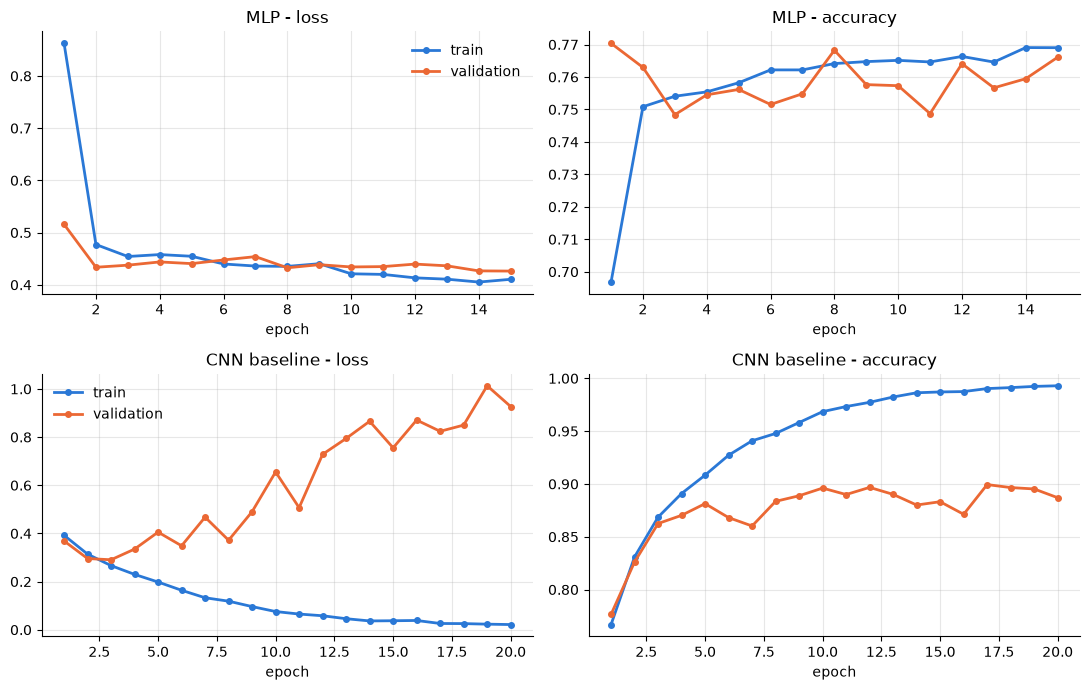

In [11]:
runs["baseline"] = train("CNN baseline", cnn, 20)

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
plot_curves(runs["MLP"]["history"], "MLP", axes[0])
plot_curves(runs["baseline"]["history"], "CNN baseline", axes[1])
plt.tight_layout()
plt.savefig(REPORTS / "final_baseline_curves.png", dpi=120)
plt.show()

In every curve figure the second curve is the validation error measured during training; it plays the role of the usual "test" curve. The real test set is scored once per model in section 8 and never drawn.

## 5. Bias and variance

The gap between train and validation accuracy measures variance (overfitting); a low train accuracy points to bias (underfitting).
Train accuracy is computed in inference mode on the whole training set (dropout and augmentation off); it can still be lower than the baseline because those methods regularise.

In [12]:
bv = {}
for k in ["MLP", "baseline"]:
    r, h = runs[k], runs[k]["history"]
    bv[k] = {"train accuracy": r["train_acc"], "validation accuracy": r["val"]["accuracy"],
             "gap": r["train_acc"] - r["val"]["accuracy"], "train loss (last)": h["loss"][-1],
             "val loss (last)": h["val_loss"][-1], "min val loss": min(h["val_loss"]),
             "epoch of min val loss": int(np.argmin(h["val_loss"])) + 1}
bv = pd.DataFrame(bv).T.rename(index={"baseline": "CNN baseline"})
bv.round(4)

,train accuracy,validation accuracy,gap,train loss (last),val loss (last),min val loss,epoch of min val loss
MLP,0.7761,0.7661,0.0100,0.4106,0.4263,0.4263,15.0
CNN baseline,0.9926,0.8870,0.1056,0.0216,0.9270,0.2907,3.0


**What we see.** The CNN baseline has a gap of 0.11 between train and validation accuracy. Its validation loss is lowest at epoch 3 and much higher at epoch 20, while validation accuracy stays roughly flat (figure of section 4).

**What it means.** The CNN baseline has low bias and high variance (overfitting): a rising validation loss with a flat accuracy suggests it becomes more confident on its errors, which section 6 tries to reduce. The MLP underfits (high bias): its train and validation accuracies are close to each other and to the majority-class accuracy. Section 6 does not address it, since the CNN baseline already scores higher.

Dropout: at each training step, half of the Dense(64) outputs are set to zero at random. It aims to correct overfitting by preventing the layer from memorising training images.

L2 regularisation: adds 1e-4 times the sum of squared weights to the loss, which penalises large weights. It aims to correct overfitting by keeping the weights small.

Early stopping: training halts when the validation loss has not improved for 3 epochs, and the weights of the best epoch are restored. It aims to correct the rise of the validation loss seen after epoch 3 in section 5.

Augmentation: training images are randomly flipped, rotated and zoomed, in training only, so the network never sees exactly the same image twice. It aims to correct overfitting by enlarging the effective training set.

Global average pooling: replaces Flatten by one average per feature map. It removes most of the Dense parameters, which aims to correct overfitting by lowering the capacity to memorise.

Choice: Dropout(0.5) after Dense(64), L2 1e-4, early stopping with patience 3, mild flip/rotation/zoom. Why: standard starting values aimed at the CNN baseline gap of 0.11 and its validation loss minimum at epoch 3 of 20 (section 5). Alternative not taken: tuning rates and strengths, which one seed cannot resolve below 3 points.

Each variant is the baseline plus one change, trained from scratch with seed 42. The combined model stacks the variants that pass the 3-point rule (the two best if none does), and the best CNN is chosen on validation balanced accuracy only. Train loss includes the L2 penalty and is measured with dropout and augmentation active, so only validation losses are compared across variants. In Keras 3.15.1 the L2 penalty is also added to the validation loss; we did not check this on the build used for this run (3.16.0.dev).

Choice: a change counts only above 3 points of validation balanced accuracy. Why: the same models changed by about 2 points between two executions, and we keep 3 points as a margin; it is a heuristic, not a statistical test (see Limits). Alternative not taken: several seeds per variant, left out by design.

In [14]:
VARIANTS = {"a. dropout 0.5": dict(dropout=True), "b. L2 1e-4": dict(l2=True), "c. early stopping": dict(early_stopping=True),
            "d. augmentation": dict(augment=True), "e. global avg pooling": dict(gap=True)}

def run_variant(name, early_stopping=False, **flags):
    cb = [keras.callbacks.EarlyStopping("val_loss", patience=3, restore_best_weights=True)] if early_stopping else []
    return train(name, build_cnn(name, **flags), 20, cb)

for name, flags in VARIANTS.items():
    runs[name] = run_variant(name, **flags)
    if name == "e. global avg pooling":
        display(describe_model(runs[name]["model"]))

base_bacc = runs["baseline"]["val"]["balanced_acc"]
gain = {k: runs[k]["val"]["balanced_acc"] - base_bacc for k in VARIANTS}
stacked = [k for k, g in gain.items() if g > NOISE] or sorted(gain, key=gain.get, reverse=True)[:2]
print("Stacked in the combined model:", stacked, "(above 3 points)" if any(g > NOISE for g in gain.values()) else "(none above 3 points: two best)")
runs["combined"] = run_variant("combined", **{k: v for s in stacked for k, v in VARIANTS[s].items()})

a. dropout 0.5          :  131 s | 20 epochs |   826,529 params | train acc 0.9698 | val acc 0.8989 | val balanced acc 0.8912
b. L2 1e-4              :  135 s | 20 epochs |   826,529 params | train acc 0.9702 | val acc 0.8938 | val balanced acc 0.8353
c. early stopping       :   46 s |  6 epochs |   826,529 params | train acc 0.8714 | val acc 0.8559 | val balanced acc 0.8700
d. augmentation         :  284 s | 20 epochs |   826,529 params | train acc 0.9212 | val acc 0.8907 | val balanced acc 0.8911
e. global avg pooling   :  141 s | 20 epochs |    27,809 params | train acc 0.8849 | val acc 0.8738 | val balanced acc 0.8928
Total 27,809 | trainable 27,809 | non-trainable 0


,name,type,output shape,params
0,rescaling_6,Rescaling,"(None, 128, 128, 3)",0
1,conv2d_15,Conv2D,"(None, 126, 126, 16)",448
2,max_pooling2d_15,MaxPooling2D,"(None, 63, 63, 16)",0
3,conv2d_16,Conv2D,"(None, 61, 61, 32)",4640
4,max_pooling2d_16,MaxPooling2D,"(None, 30, 30, 32)",0
5,conv2d_17,Conv2D,"(None, 28, 28, 64)",18496
6,max_pooling2d_17,MaxPooling2D,"(None, 14, 14, 64)",0
7,global_average_pooling2d,GlobalAveragePooling2D,"(None, 64)",0
8,dense_13,Dense,"(None, 64)",4160
9,dense_14,Dense,"(None, 1)",65


Stacked in the combined model: ['e. global avg pooling', 'a. dropout 0.5'] (none above 3 points: two best)
combined                :  135 s | 20 epochs |    27,809 params | train acc 0.8875 | val acc 0.8817 | val balanced acc 0.8974


In [15]:
CNN_ROWS = ["baseline", *VARIANTS, "combined"]
rows = {}
for k in CNN_ROWS:
    r, d = runs[k], runs[k]["val"]["balanced_acc"] - base_bacc
    h = r["history"]
    rows[k] = {"epochs": r["epochs"], "params": r["params"], "train accuracy": r["train_acc"],
               "validation accuracy": r["val"]["accuracy"], "gap": r["train_acc"] - r["val"]["accuracy"],
               "val balanced accuracy": r["val"]["balanced_acc"], "val F1 Photo": r["val"]["f1"],
               "train loss (last)": h["loss"][-1], "val loss (last)": h["val_loss"][-1],
               "min val loss": min(h["val_loss"]), "epoch of min val loss": int(np.argmin(h["val_loss"])) + 1,
               "change vs baseline (points)": 100 * d,
               "above noise (3 points)?": "-" if k == "baseline" else ("yes" if d > NOISE else "no")}
val_summary = pd.DataFrame(rows).T
val_summary.index.name = "variant"
val_summary.to_csv(REPORTS / "final_val_summary.csv")
num = val_summary.columns[2:-1]
val_summary[num] = val_summary[num].astype(float).round(4)
val_summary["change vs baseline (points)"] = val_summary["change vs baseline (points)"].round(2)
display(val_summary)

best_cnn = max(CNN_ROWS[1:], key=lambda k: runs[k]["val"]["balanced_acc"])
print("Best CNN variant on validation:", best_cnn)
for k in CNN_ROWS:  # free the models that are not evaluated on test
    if k not in ("baseline", best_cnn):
        runs[k]["model"] = None

,epochs,params,train accuracy,validation accuracy,gap,val balanced accuracy,val F1 Photo,train loss (last),val loss (last),min val loss,epoch of min val loss,change vs baseline (points),above noise (3 points)?
variant,,,,,,,,,,,,,
baseline,20,826529,0.9926,0.8870,0.1056,0.8636,0.7820,0.0216,0.9270,0.2907,3.0,0.00,-
a. dropout 0.5,20,826529,0.9698,0.8989,0.0709,0.8912,0.8112,0.1018,0.4364,0.3056,14.0,2.76,no
b. L2 1e-4,20,826529,0.9702,0.8938,0.0764,0.8353,0.7706,0.1376,0.8587,0.3339,3.0,-2.84,no
c. early stopping,6,826529,0.8714,0.8559,0.0155,0.8700,0.7555,0.1651,0.3873,0.3338,3.0,0.64,no
d. augmentation,20,826529,0.9212,0.8907,0.0306,0.8911,0.8018,0.1280,0.4529,0.3102,14.0,2.75,no
e. global avg pooling,20,27809,0.8849,0.8738,0.0111,0.8928,0.7853,0.2087,0.2603,0.2583,17.0,2.92,no
combined,20,27809,0.8875,0.8817,0.0058,0.8974,0.7957,0.2340,0.2582,0.2493,19.0,3.38,yes


Best CNN variant on validation: combined


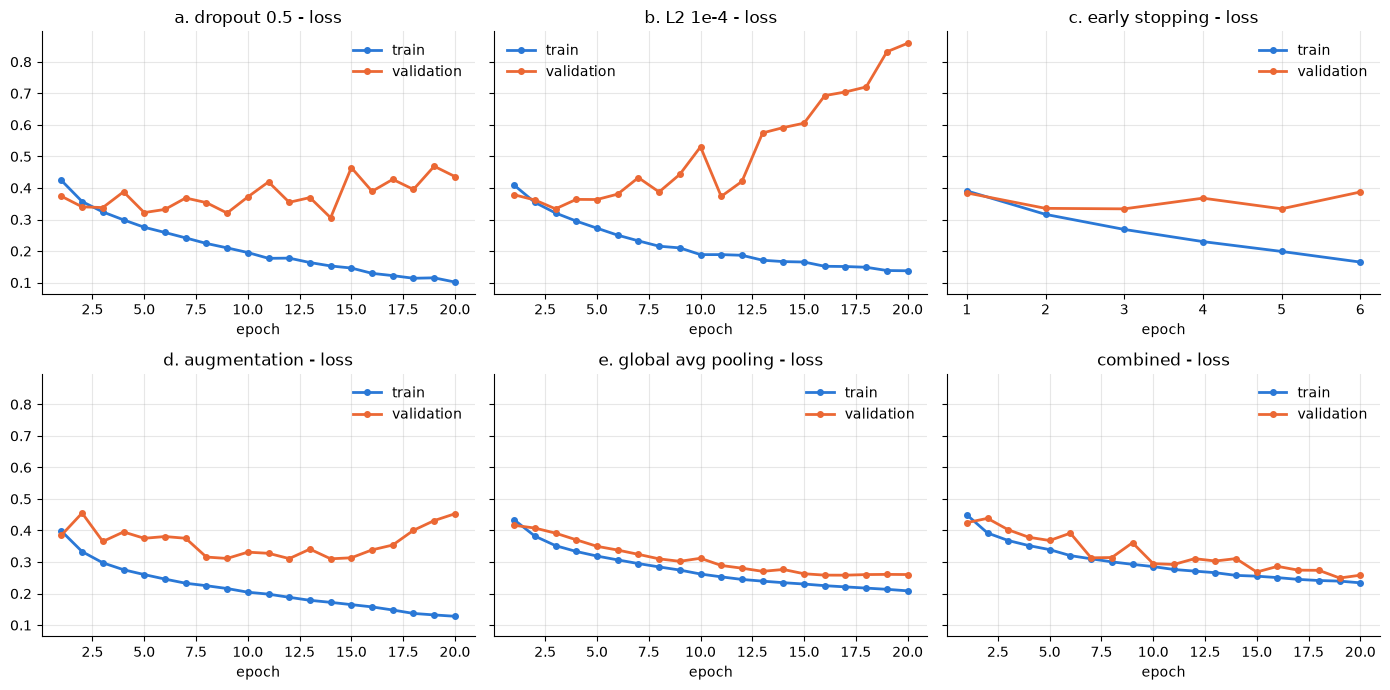

In [15]:
# Validation loss is class-weighted like the train loss; the baseline curves are in the section 4 figure
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharey=True)
for ax, k in zip(axes.ravel(), CNN_ROWS[1:]):
    plot_curves(runs[k]["history"], k, axes=[ax])
plt.tight_layout()
plt.savefig(REPORTS / "final_variant_curves.png", dpi=120)
plt.show()

**What we see.** Only the combined model passes the 3-point rule ("above noise" column); dropout, augmentation and global average pooling stay just below it. At the last epoch, the validation loss is 0.26 for the combined model and 0.93 for the baseline.

**What it means.** We select the combined model because it has the best validation balanced accuracy, but its lead over global average pooling alone is under 3 points, so the ranking among the top variants is not conclusive. The two models with global average pooling have the smallest train-validation gap and far fewer parameters, which suggests that cutting the Dense parameters reduces overfitting more than regularising them; one seed cannot confirm it.

## 7. Pretrained MobileNetV2

MobileNetV2 pretrained on ImageNet is used without its classifier (include_top=False, global average pooling), with its own preprocess_input inside the model to map 0-255 pixels to [-1, 1]. The backbone is called with training=False and the head is Dropout(0.2) + Dense(1).

Transfer learning: the convolution filters learned on ImageNet are reused instead of learned from our images, and only a small head is fitted. It aims to correct the overfitting of the scratch CNN seen in section 5.

Choice: train the head alone (10 epochs, lr 1e-3), then unfreeze the last 30 backbone layers with BatchNorm frozen (10 epochs, lr 1e-5); phase 2 is kept only if it gains more than 3 points on validation. Why: the frozen backbone is the simpler model, and the same noise rule applies to every comparison. Alternative not taken: unfreezing the whole backbone, or tuning 30 layers and 1e-5.

In [17]:
keras.utils.set_random_seed(SEED)
try:
    backbone = keras.applications.MobileNetV2(input_shape=(SIZE, SIZE, 3), include_top=False, weights="imagenet", pooling="avg")
except Exception as e:
    print(f"ImageNet weights could not be loaded: {type(e).__name__}: {e}")
    raise
backbone.trainable = False
inputs = keras.Input((SIZE, SIZE, 3))
x = backbone(keras.applications.mobilenet_v2.preprocess_input(inputs), training=False)
outputs = keras.layers.Dense(1, activation="sigmoid")(keras.layers.Dropout(0.2)(x))
pretrained = keras.Model(inputs, outputs, name="mobilenetv2_transfer")

def compile_pretrained(lr):
    pretrained.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy", metrics=["accuracy"])

def n_trainable(m):
    return int(sum(np.prod(w.shape) for w in m.trainable_weights))

compile_pretrained(1e-3)
print(f"Phase 1: total {pretrained.count_params():,} | trainable {n_trainable(pretrained):,}")
phase = {"phase 1: frozen": train("phase 1: frozen", pretrained, 10)}
phase["phase 1: frozen"]["trainable"] = n_trainable(pretrained)
weights_phase1 = pretrained.get_weights()

backbone.trainable = True
for layer in backbone.layers[:-30]:
    layer.trainable = False
for layer in backbone.layers[-30:]:
    if isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False
compile_pretrained(1e-5)  # recompile so the new trainable flags apply
print(f"Phase 2: total {pretrained.count_params():,} | trainable {n_trainable(pretrained):,}")
t = time.time()
h2 = pretrained.fit(X["train"], y["train"], validation_data=(X["val"], y["val"], sw_val), epochs=20, initial_epoch=10,
                    batch_size=BATCH, class_weight=cw, verbose=0)
val2 = evaluate(y["val"], pretrained.predict(X["val"], verbose=0), origin["val"])
phase["phase 2: fine-tuned"] = {"val": val2, "trainable": n_trainable(pretrained), "params": pretrained.count_params(),
                                "train_acc": ((pretrained.predict(X["train"], verbose=0).ravel() >= 0.5) == y["train"]).mean()}
print(f"Phase 2: {time.time() - t:.0f} s | val balanced acc {val2['balanced_acc']:.4f}")
history_pt = {k: phase["phase 1: frozen"]["history"][k] + h2.history[k] for k in h2.history}

Phase 1: total 2,259,265 | trainable 1,281
phase 1: frozen         :  105 s | 10 epochs | 2,259,265 params | train acc 0.9770 | val acc 0.9659 | val balanced acc 0.9617
Phase 2: total 2,259,265 | trainable 1,512,001
Phase 2: 111 s | val balanced acc 0.9760


,trainable params,total params,train accuracy,validation accuracy,gap,val balanced accuracy,val F1 Photo
phase,,,,,,,
phase 1: frozen,1281.0,2259265.0,0.977,0.9659,0.0111,0.9617,0.9328
phase 2: fine-tuned,1512001.0,2259265.0,1.000,0.9825,0.0175,0.9760,0.9646


Selected on validation: phase 1: frozen | phase 2 minus phase 1: +1.44 points (noise threshold 3)


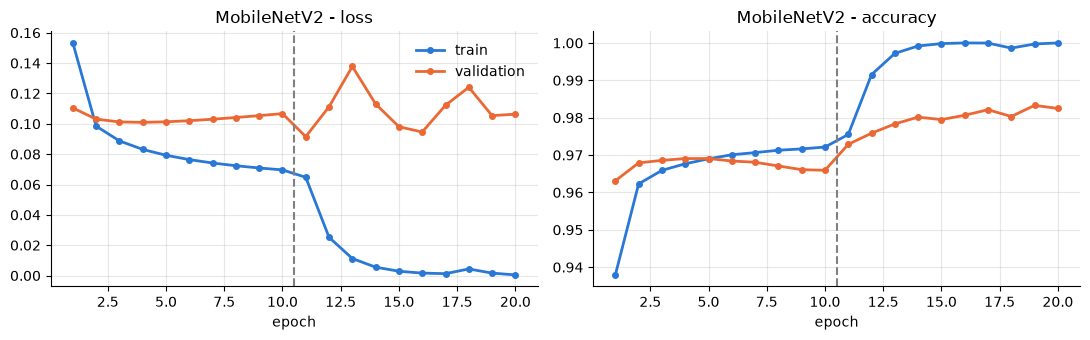

Total 2,259,265 | trainable 1,512,001 | non-trainable 747,264


,name,type,output shape,params
0,input_layer_9,InputLayer,"(None, 128, 128, 3)",0
1,mobilenetv2_1.00_128,Functional,"(None, 1280)",2257984
2,dropout_2,Dropout,"(None, 1280)",0
3,dense_17,Dense,"(None, 1)",1281


In [17]:
pt_table = pd.DataFrame({k: {"trainable params": r["trainable"], "total params": r["params"], "train accuracy": r["train_acc"],
                             "validation accuracy": r["val"]["accuracy"], "gap": r["train_acc"] - r["val"]["accuracy"],
                             "val balanced accuracy": r["val"]["balanced_acc"], "val F1 Photo": r["val"]["f1"]}
                         for k, r in phase.items()}).T
pt_table.index.name = "phase"
display(pt_table.astype(float).round(4))
# Phase 2 is kept only if it beats phase 1 on validation balanced accuracy by more than NOISE
gain_phase2 = pt_table["val balanced accuracy"].iloc[1] - pt_table["val balanced accuracy"].iloc[0]
best_phase = "phase 2: fine-tuned" if gain_phase2 > NOISE else "phase 1: frozen"
if best_phase == "phase 1: frozen":
    pretrained.set_weights(weights_phase1)
print(f"Selected on validation: {best_phase} | phase 2 minus phase 1: {100 * gain_phase2:+.2f} points (noise threshold {100 * NOISE:.0f})")

axes = plot_curves(history_pt, "MobileNetV2")
for ax in axes:
    ax.axvline(10.5, color="grey", ls="--")
plt.tight_layout()
plt.savefig(REPORTS / "final_pretrained_curves.png", dpi=120)
plt.show()
pretrained.save(MODELS / "final_pretrained.keras")
display(describe_model(pretrained))

The dashed line marks the start of fine-tuning; losses are class-weighted on both sides and accuracies are plain.

The backbone (MobileNetV2 pretrained on ImageNet) is shown as one block. true_divide and subtract apply preprocess_input, which maps pixels from [0, 255] to [-1, 1]. Only the Dropout and Dense(1) head is new. The layer table is printed after phase 2; the delivered model is phase 1 (1,281 trainable weights).

**What we see.** Fine-tuning (phase 2) adds 1.4 points of validation balanced accuracy over the frozen backbone, and the frozen backbone has a train-validation gap of only 0.01.

**What it means.** Our rule keeps phase 1: 1.4 points is under the 3-point threshold and the frozen model is simpler (far fewer trainable weights in the table), so fine-tuning is not shown to help. With the backbone frozen, only the Dropout + Dense head is fitted to our images, and it already scores above the best scratch CNN on validation (section 6).

## 8. Final evaluation on the test set

Each neural network is evaluated once here, on the natural test distribution; the two reference models were scored once in section 3. The best CNN variant and the pretrained phase were chosen on validation before this cell.

Choice: fixed 0.5 threshold on the sigmoid output, not tuned. Why: the standard decision point; PR-AUC is reported next to it without threshold. Alternative not taken: a threshold tuned on validation.

In [18]:
NETS = {"MLP": runs["MLP"]["model"], "CNN baseline": runs["baseline"]["model"],
        f"CNN best variant ({best_cnn})": runs[best_cnn]["model"], f"MobileNetV2 ({best_phase})": pretrained}
for k, m in NETS.items():
    test_eval[k] = evaluate(y["test"], m.predict(X["test"], verbose=0), origin["test"])
test_table = pd.DataFrame({k: {m: v[m] for m in METRICS} for k, v in test_eval.items()}).T
test_table.index.name = "model"
test_table.round(4).to_csv(REPORTS / "final_test_results.csv")
print(f"Test set (n = {len(y['test'])})")
test_table.round(4)

Test set (n = 6046)


,precision,recall,f1,balanced_acc,pr_auc,accuracy
model,,,,,,
majority,0.0000,0.0000,0.0000,0.5000,0.2479,0.7521
decision tree (metadata),0.9641,0.9853,0.9746,0.9866,0.9849,0.9873
MLP,0.5123,0.8913,0.6506,0.8058,0.6323,0.7627
CNN baseline,0.7421,0.8252,0.7814,0.8653,0.8218,0.8855
CNN best variant (combined),0.6868,0.9346,0.7917,0.8970,0.8854,0.8781
MobileNetV2 (phase 1: frozen),0.9184,0.9540,0.9359,0.9630,0.9823,0.9676


Interpretation: the best CNN has a higher balanced accuracy than the baseline but a lower accuracy, with more recall and less precision, so it trades precision for recall; the MLP shows the same pattern. Class weights probably push the predictions towards Photo (not tested without weights).

The best CNN has a higher balanced accuracy than the baseline but a lower accuracy, with more recall and less precision: it trades precision for recall, as the MLP does. Class weights probably push the predictions towards Photo; we did not test this without weights.

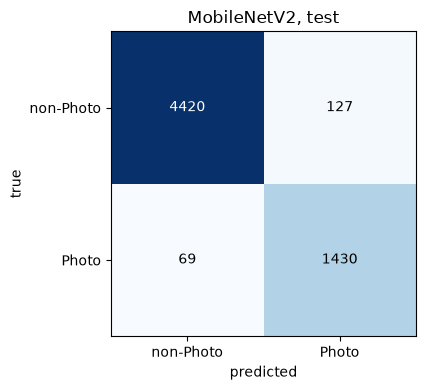

,majority,decision tree (metadata),MLP,CNN baseline,CNN best variant (combined),MobileNetV2 (phase 1: frozen)
origin,,,,,,
Painting,0.0,0.0320,0.6667,0.2520,0.3793,0.0693
Photo,1.0,0.0147,0.1087,0.1748,0.0654,0.0460
Schematics,0.0,0.0052,0.2036,0.0389,0.0524,0.0172
Sketch,0.0,0.0000,0.0000,0.0000,0.0000,0.0000
Text,0.0,0.0000,0.0000,0.0000,0.0000,0.0000


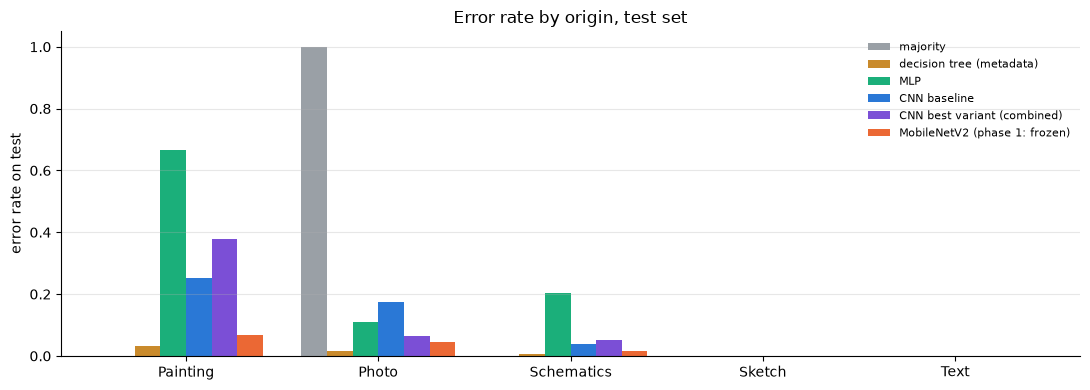

In [19]:
k_pt = f"MobileNetV2 ({best_phase})"
cm = test_eval[k_pt]["cm"]
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, v, ha="center", va="center", color="white" if v > cm.max() / 2 else "black")
ax.set_xticks([0, 1], ["non-Photo", "Photo"])
ax.set_yticks([0, 1], ["non-Photo", "Photo"])
ax.set(xlabel="predicted", ylabel="true", title="MobileNetV2, test")
plt.tight_layout()
plt.savefig(REPORTS / "final_pretrained_confusion.png", dpi=120)
plt.show()

err = pd.DataFrame({k: v["error_by_origin"] for k, v in test_eval.items()})
err.index.name = "origin"
display(err.round(4))
colors = ["#9aa0a6", "#c98a2b", "#1baf7a", "#2a78d6", "#7b4fd6", "#eb6834"]
ax = err.plot.bar(figsize=(11, 4), color=colors, rot=0, width=0.8)
ax.set(ylabel="error rate on test", title="Error rate by origin, test set", xlabel="")
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.savefig(REPORTS / "final_error_by_origin.png", dpi=120)
plt.show()

**What we see.** Painting has the highest error rate among the non-Photo origins, for every trained model and for the tree: 0.38 for the best CNN and 0.07 for MobileNetV2. For every trained model the order is the same: Text and Sketch at zero, then Schematics, then Painting.

**What it means.** The false Photo are mostly paintings, probably because some paintings look like photographs; we did not test this. Sketch has only 211 test images, so its error rate is not interpretable.

## 9. Key takeaways

- Image dimensions alone nearly separate the classes on validation (section 3), so the metadata tree, not the majority class, is the bar to beat.

- A CNN trained from scratch overfits (section 5). Global average pooling removes most parameters and shrinks the gap; dropout regularises without reducing them. Only the combined model passes the 3-point rule on validation, and its lead over the single variants is not conclusive (section 6).

- MobileNetV2 with a frozen backbone is the model to deliver (sections 7 and 8); it is 2.4 points below the tree, within the 3-point margin, so the tree is not shown to be better.

- The scratch networks favour recall over precision, probably through class weights, which we did not test (section 8).
- Painting is the hardest non-Photo origin for every trained model (section 8).

- We did not test whether the networks use image size as the tree does (section 3).

## 10. Limits and reproducibility

In [20]:
print(f"Total notebook runtime: {(time.time() - T0) / 60:.1f} min on {GPU_NAME}")

Total notebook runtime: 22.1 min on NVIDIA GeForce RTX 5060 Laptop GPU


- Single run (seed 42). Two executions of the same code on the same machine gave scores that differ by up to about 2 points (the L2 variant), and dropout and global average pooling passed the 3-point rule in only one of them. This is why we treat differences under 3 points as not conclusive. The noise of MobileNetV2 was not measured.

- The environment uses pre-release builds (TensorFlow 2.22.0-rc0, Keras 3.16.0.dev), so reruns on other versions can differ slightly.

- The tree nearly separates the classes with dimensions alone, and we did not build a size-matched test set, so we do not know whether the networks rely on image size.

- Near-duplicates (resized or recompressed copies) are not detected; only exact MD5 duplicates are removed. Sketch is mostly grayscale PNG and has only 211 test images.

- Only 128x128 was used (the aspect ratio is distorted, 224x224 was not tested); the architectures, batch size, learning rate and the 0.5 threshold were not tuned.

- The MobileNetV2 weights are downloaded on first run (internet needed once); ImageNet contains many photos, which may favour it.